[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nlavadodatasci/atd-megaf-fiabilidade/blob/main/T2_weibull/T2_weibull.ipynb)

# T2 — Estimação dos parâmetros da Weibull

**ATD — MEGAF 2026/27 · Atividade de Fiabilidade · Tema T2**

Como se obtêm $\beta$ (forma) e $\eta$ (escala) a partir de tempos até à falha? Este *notebook* mostra os dois métodos mais usados, o gráfico de Weibull e a máxima verosimilhança, numa amostra de 50 tempos tirada dos dados da aula.

**Como usar:** execute as células por ordem (Shift+Enter). As primeiras secções estão resolvidas, com dados da aula ou com exemplos inventados, para mostrar o método. A última secção, **A sua vez**, lê os dados da instalação e deixa pistas: o trabalho do grupo começa aí. O capítulo deste tema no documento de apoio explica cada passo.

## 1. Uma amostra de 50 tempos dos dados da aula

In [1]:
import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

REPO = "https://raw.githubusercontent.com/nlavadodatasci/atd-megaf-fiabilidade/main/dados/"

def obter(ficheiro):
    """Vai buscar o ficheiro ao repositório. Se falhar, abre uma janela
    para o escolher no seu computador."""
    if not os.path.exists(ficheiro):
        try:
            urllib.request.urlretrieve(REPO + ficheiro, ficheiro)
        except Exception:
            from google.colab import files
            print("Escolha no seu computador o ficheiro", ficheiro)
            carregados = files.upload()
            if ficheiro not in carregados:               # veio com outro nome: renomeia
                os.rename(list(carregados)[0], ficheiro)
    return ficheiro

aula = pd.read_excel(obter("tempo_falhas_aula.xlsx"), sheet_name="tempo_falhas", usecols="A:B")
t = aula.iloc[:, 1].dropna().to_numpy()      # tempos até à falha da aula (horas)
print("Número de tempos:", len(t), "  MTBF:", round(t.mean(), 2))

rng = np.random.default_rng(2026)
amostra = np.sort(rng.choice(t, size=50, replace=False))     # 50 tempos, ordenados
print(amostra[:5].round(0), "...", amostra[-3:].round(0))

Número de tempos: 9998   MTBF: 8738.14
[ 96. 218. 735. 851. 900.] ... [20227. 21884. 28996.]


## 2. Método 1: o gráfico de Weibull

Partindo de $F(t) = 1 - e^{-(t/\eta)^\beta}$ e aplicando logaritmos duas vezes:

$$\ln\big(-\ln(1 - F(t))\big) = \beta \ln t - \beta \ln \eta$$

É a equação de uma reta $y = \beta x + b$, com $x = \ln t$ e $y = \ln(-\ln(1-F))$. Se os dados seguirem uma Weibull, os pontos $(x, y)$ alinham-se, o declive é $\beta$ e $\eta = e^{-b/\beta}$.

Falta estimar $F$ em cada tempo observado. Com os tempos ordenados, usa-se a aproximação de Bernard (*median ranks*): para o $i$-ésimo tempo, $\hat F_i = \dfrac{i - 0{,}3}{n + 0{,}4}$.

Tudo isto se faz em Excel: ordenar, três colunas de fórmulas e as funções `=SLOPE(...)` e `=INTERCEPT(...)`.

Gráfico de Weibull:  beta = 1.027   eta = 8212 h   R2 = 0.988


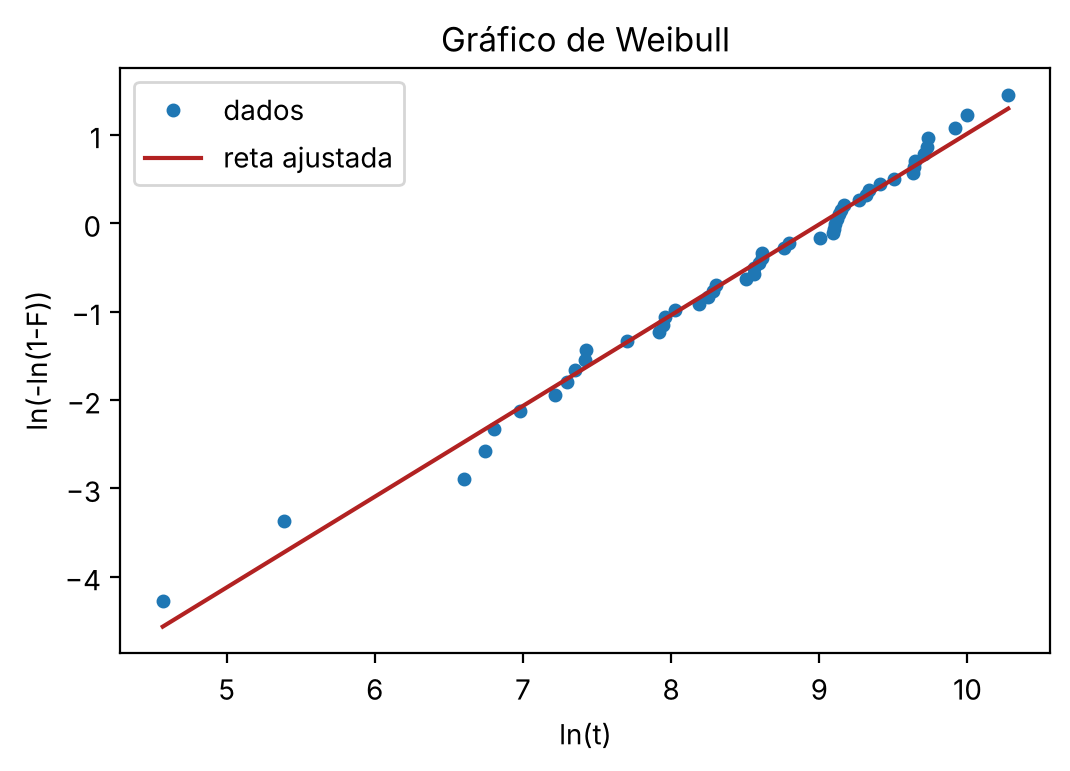

In [2]:
n = len(amostra)
i = np.arange(1, n + 1)
F = (i - 0.3) / (n + 0.4)                  # median ranks
x = np.log(amostra)
y = np.log(-np.log(1 - F))

reta = stats.linregress(x, y)
beta_g = reta.slope
eta_g = np.exp(-reta.intercept / beta_g)
print(f"Gráfico de Weibull:  beta = {beta_g:.3f}   eta = {eta_g:.0f} h   R2 = {reta.rvalue**2:.3f}")

plt.figure(figsize=(6, 3.8))
plt.plot(x, y, "o", ms=4, label="dados")
plt.plot(x, reta.intercept + reta.slope * x, color="firebrick", label="reta ajustada")
plt.xlabel("ln(t)"); plt.ylabel("ln(-ln(1-F))"); plt.legend(); plt.title("Gráfico de Weibull")
plt.show()

## 3. Método 2: máxima verosimilhança

A máxima verosimilhança procura os valores de $\beta$ e $\eta$ que tornam os dados observados mais prováveis. Não tem fórmula fechada para a Weibull; o `scipy` resolve numericamente. O argumento `floc=0` fixa o parâmetro de localização em zero (Weibull de dois parâmetros).

In [3]:
beta_mv, _, eta_mv = stats.weibull_min.fit(amostra, floc=0)
print(f"Máxima verosimilhança:  beta = {beta_mv:.3f}   eta = {eta_mv:.0f} h")

Máxima verosimilhança:  beta = 1.139   eta = 8030 h


Os dois métodos dão valores parecidos, mas não iguais. Os dados da aula seguem uma exponencial, que é uma Weibull com $\beta = 1$: os dois $\beta$ estimados andam perto de 1, como deviam.

## 4. Que confiança merece a estimativa?

Com outros 50 tempos, as estimativas seriam outras. A célula seguinte repete a estimação em cinco amostras diferentes dos dados da aula, para ver quanto varia.

In [4]:
for semente in range(5):
    outra = np.random.default_rng(semente).choice(t, size=50, replace=False)
    b, _, e = stats.weibull_min.fit(outra, floc=0)
    print(f"amostra {semente}:  beta = {b:.2f}   eta = {e:.0f} h")

amostra 0:  beta = 0.86   eta = 6874 h
amostra 1:  beta = 0.97   eta = 8621 h
amostra 2:  beta = 1.10   eta = 9678 h
amostra 3:  beta = 0.95   eta = 7876 h
amostra 4:  beta = 1.15   eta = 11726 h


Nos dados da instalação só há uma amostra de cada componente. A técnica de *bootstrap* contorna isso: tiram-se muitas amostras **com reposição** da própria amostra (`rng.choice(dados, size=len(dados), replace=True)`), estima-se em cada uma, e os percentis 2,5 e 97,5 das estimativas dão um intervalo de confiança aproximado.

## 5. A sua vez

Pistas:

1. Aplique os dois métodos ao gerador e ao controlador. Os pontos do gráfico de Weibull alinham-se?
2. Interprete o $\beta$ de cada um: é menor, igual ou maior do que 1? O que diz isso sobre a taxa de falha (secção 4.4 do documento de apoio)?
3. Construa um intervalo de confiança para $\beta$ por *bootstrap*. O intervalo contém o valor 1? Porque é que essa pergunta é importante?
4. Repita com apenas 15 unidades de cada componente. O que acontece ao intervalo?
5. Desenhe $R(t)$ de cada componente com `stats.weibull_min(beta, scale=eta).sf(x)` e leia o valor para a missão de 2000 h.

In [5]:
ensaios = pd.read_excel(obter("dados_fiabilidade.xlsx"), sheet_name="ensaios_vida")

componente = "Gerador"                         # depois: "Controlador"
tc = np.sort(ensaios[ensaios["componente"] == componente]["tempo_ate_falha_h"].to_numpy())
print(componente, "- número de tempos:", len(tc))

# Método 1: median ranks, x = ln(t), y = ln(-ln(1-F)), stats.linregress(x, y)
# Método 2: stats.weibull_min.fit(tc, floc=0)

Gerador - número de tempos: 50
